Домашнее задание по теме 7

$\textbf{Часть 1}$

а) постройте гистограммы для признака Sales и его логарифма; 

In [87]:
import pandas as pd
import seaborn as sb
import numpy as np
import matplotlib.pyplot as plt

d = pd.read_table('data/CarSales.txt',  sep='\t')
d

,Manufact,Model,Sales,Type,Price,Engine_s,Horsepow,Wheelbas,Width,Length,Curb_wgt,Fuel_cap,Miles_gal
0,Acura,Integra,"16,919",0,"21,5","1,8",140,"101,2","67,3","172,4","2,639","13,2",28.0
1,Acura,TL,"39,384",0,"28,4","3,2",225,"108,1","70,3","192,9","3,517","17,2",25.0
2,Acura,RL,"8,588",0,42,"3,5",210,"114,6","71,4","196,6","3,85",18,22.0
3,Audi,A4,"20,397",0,"23,99","1,8",150,"102,6","68,2",178,"2,998","16,4",27.0
4,Audi,A6,"18,78",0,"33,95","2,8",200,"108,7","76,1",192,"3,561","18,5",22.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
149,Volvo,V40,"3,545",0,"24,4","1,9",160,"100,5","67,6","176,6","3,042","15,8",25.0
150,Volvo,S70,"15,245",0,"27,5","2,4",168,"104,9","69,3","185,9","3,208","17,9",25.0
151,Volvo,V70,"17,531",0,"28,8","2,4",168,"104,9","69,3","186,2","3,259","17,9",25.0
152,Volvo,C70,"3,493",0,"45,5","2,3",236,"104,9","71,5","185,7","3,601","18,5",23.0


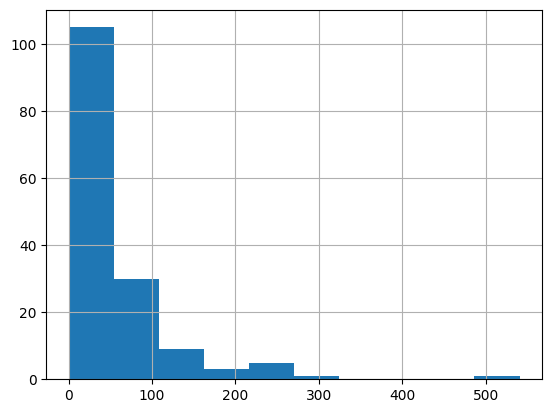

In [88]:
d['Sales'] = d['Sales'].str.replace(',', '.').astype(float)
plt.hist(d['Sales'])
plt.grid(True)
plt.show()

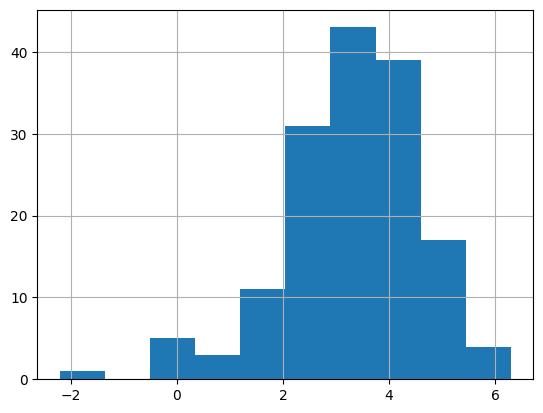

In [89]:
plt.hist(np.log(d['Sales']))
plt.grid(True)
plt.show()

б) постройте диаграмму рассеяния для Miles_gal и логарифма Sales; 

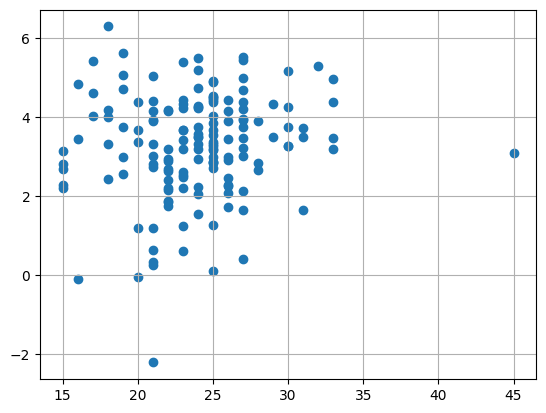

In [90]:
plt.scatter(d['Miles_gal'],np.log(d['Sales']))
plt.grid(True)
plt.show()

в) замените 2 выделяющихся наблюдения на пропуски и снова постройте диаграмму рассеяния; 

In [91]:
d.loc[d['Miles_gal'] > 40, 'Miles_gal'] = np.nan
d.loc[np.log(d['Sales']) < -1, 'Sales'] = np.nan
d = d.dropna(subset=['Miles_gal','Sales']).copy()

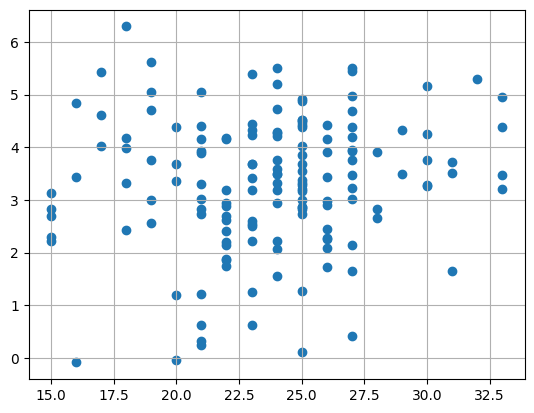

In [92]:
plt.scatter(d['Miles_gal'],np.log(d['Sales']))
plt.grid(True)
plt.show()

г) вычислите коэффициент корреляции Пирсона и проверьте значимость корреляционной связи 
признака Miles_gal и логарифма признака Sales на уровне значимости 0,05. 

In [93]:
from scipy.stats import pearsonr

corr_coef, p_value = pearsonr(d['Miles_gal'], np.log(d['Sales']))

print(f"Коэффициент корреляции Пирсона: r = {corr_coef}")
print(f"P-value: {p_value:}")

Коэффициент корреляции Пирсона: r = 0.12609615690004286
P-value: 0.1241511116676427


На уровне 0.05 не можем утверждать об отсутствии линейной связи.

$\textbf{Часть 2}$

a) проверьте значимость на уровне 0,05 корреляционной связи признака Miles_gal и логарифма 
признака Sales отдельно для легковых машин и для грузовиков (укажите два p-value); 

In [94]:
s = d[d['Type'] == 0].copy()
t = d[d['Type'] == 1].copy()
corr_coef, p_value = pearsonr(s['Miles_gal'], np.log(s['Sales']))

print(f"Коэффициент корреляции Пирсона для легковых машин: r = {corr_coef}")
print(f"P-value: {p_value}")

corr_coef, p_value = pearsonr(t['Miles_gal'], np.log(t['Sales']))

print(f"Коэффициент корреляции Пирсона для грузовых машин: r = {corr_coef}")
print(f"P-value: {p_value}")


Коэффициент корреляции Пирсона для легковых машин: r = 0.43956918548248963
P-value: 1.5515485814078976e-06
Коэффициент корреляции Пирсона для грузовых машин: r = 0.20257062834533685
P-value: 0.20999169952213542


Для легковых машин на уровне 0.05 можем отвергнуть гипотезу о линейной независимости.

б) постройте диаграмму рассеяния для Miles_gal и логарифма Sales с раскраской в разные цвета 
точек, соответствующих легковым машинам, и точек, соответствующих грузовикам;

<Axes: xlabel='Miles_gal', ylabel='Log_Sales'>

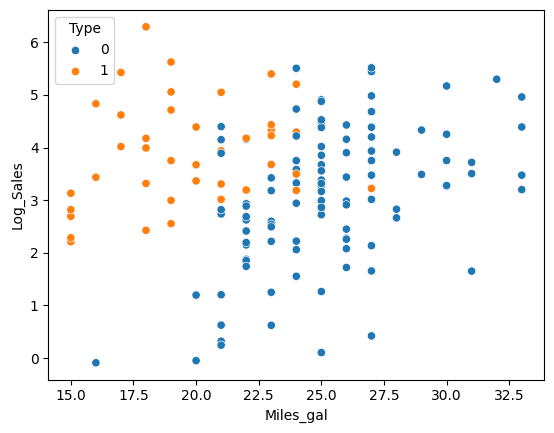

In [95]:
d['Log_Sales'] = np.log(d['Sales'])
sb.scatterplot(d, x='Miles_gal',y='Log_Sales',hue='Type')

в) для легковых машин вычислите ранговый коэффициент корреляции Спирмена и определите 
фактический уровень значимости (p-value) отличия его от нуля.

In [ ]:
from scipy.stats import spearmanr

s['Log_Sales'] = np.log(s['Sales'])
rho, p_value = spearmanr(s['Miles_gal'], s['Log_Sales'])

print(f"Коэффициент Спирмена: {rho}")
print(f"P-value: {p_value}")

Коэффициент Спирмена: 0.4102413071251217
P-value: 8.545192754992644e-06


На уровне 0.05 можем отвергнуть гипотезу об отсутствии монотонной связи.